In [2]:

# 1. Install gdown
!pip -q install gdown

# 2. Download your Google Drive ZIP file
import gdown
import os

file_id = "1njl-hWUG7OEQVilJ4f8w77YuZe7EXrtM"
zip_path = "/kaggle/working/dataset.zip"

url = f"https://drive.google.com/uc?id={file_id}"

gdown.download(url, zip_path, quiet=False)

# 3. Verify the download
if os.path.exists(zip_path):
    print(f"Download complete: {zip_path}")
    print(f"File size: {os.path.getsize(zip_path) / (1024**3):.2f} GB")
else:
    print("Download failed. Check the Drive sharing permissions.")


Downloading...
From (original): https://drive.google.com/uc?id=1njl-hWUG7OEQVilJ4f8w77YuZe7EXrtM
From (redirected): https://drive.google.com/uc?id=1njl-hWUG7OEQVilJ4f8w77YuZe7EXrtM&confirm=t&uuid=19dc6664-e849-49ec-bfe2-a92bd14e9ad0
To: /kaggle/working/dataset.zip
100%|██████████| 804M/804M [00:06<00:00, 127MB/s]  


Download complete: /kaggle/working/dataset.zip
File size: 0.75 GB


In [3]:

import zipfile
import os

zip_path = "/kaggle/working/dataset.zip"
extract_path = "/kaggle/working/dataset"

if os.path.isfile(zip_path) and zipfile.is_zipfile(zip_path):
    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(extract_path)
    print("Extracted to:", extract_path)
    print("Files:", os.listdir(extract_path)[:20])
else:
    print("ZIP file is missing, incomplete, or invalid.")


Extracted to: /kaggle/working/dataset
Files: ['noise_project_v2']


In [4]:

import os

folder = "/kaggle/working/dataset/noise_project_v2"

for root, dirs, files in os.walk(folder):
    level = root.replace(folder, "").count(os.sep)
    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

    subindent = "    " * (level + 1)
    for file in files[:20]:
        print(f"{subindent}{file}")

    if level >= 3:
        dirs.clear()


noise_project_v2/
    clean_list.csv
    noise_manifest_v2.json
    noisy_metadata_v2.csv
    b6000_split.csv
    clean_500/
        V/
            00002435_V_500_roll_09.png
            00002596_V_500_roll_01.png
            00002578_V_500_roll_06.png
            00002508_V_500_roll_03.png
            00002307_V_500_roll_07.png
            00002440_V_500_roll_03.png
            00002355_V_500_roll_03.png
            00002330_V_500_roll_02.png
            00002313_V_500_roll_04.png
            00002374_V_500_roll_02.png
            00002488_V_500_roll_05.png
            00002426_V_500_roll_02.png
            00002352_V_500_roll_06.png
            00002401_V_500_roll_02.png
            00002391_V_500_roll_01.png
            00002571_V_500_roll_09.png
            00002488_V_500_roll_09.png
            00002367_V_500_roll_03.png
            00002646_V_500_roll_05.png
            00002304_V_500_roll_04.png
        U/
            00002434_U_500_roll_04.png
            00002341_U_500_roll_06

In [5]:

from pathlib import Path
from collections import Counter

folder = Path("/kaggle/working/dataset/noise_project_v2")

files = [p for p in folder.rglob("*") if p.is_file()]

print("Total files:", len(files))
print("\nFile types:")
print(Counter(p.suffix.lower() or "[no extension]" for p in files))

print("\nFirst 30 file paths:")
for p in files[:30]:
    print(p.relative_to(folder))


Total files: 4984

File types:
Counter({'.png': 4980, '.csv': 3, '.json': 1})

First 30 file paths:
clean_list.csv
noise_manifest_v2.json
noisy_metadata_v2.csv
b6000_split.csv
noisy_500_v2/V/00002435_V_500_roll_09.png
noisy_500_v2/V/00002596_V_500_roll_01.png
noisy_500_v2/V/00002578_V_500_roll_06.png
noisy_500_v2/V/00002508_V_500_roll_03.png
noisy_500_v2/V/00002307_V_500_roll_07.png
noisy_500_v2/V/00002440_V_500_roll_03.png
noisy_500_v2/V/00002355_V_500_roll_03.png
noisy_500_v2/V/00002330_V_500_roll_02.png
noisy_500_v2/V/00002313_V_500_roll_04.png
noisy_500_v2/V/00002374_V_500_roll_02.png
noisy_500_v2/V/00002488_V_500_roll_05.png
noisy_500_v2/V/00002426_V_500_roll_02.png
noisy_500_v2/V/00002352_V_500_roll_06.png
noisy_500_v2/V/00002401_V_500_roll_02.png
noisy_500_v2/V/00002391_V_500_roll_01.png
noisy_500_v2/V/00002571_V_500_roll_09.png
noisy_500_v2/V/00002488_V_500_roll_09.png
noisy_500_v2/V/00002367_V_500_roll_03.png
noisy_500_v2/V/00002646_V_500_roll_05.png
noisy_500_v2/V/00002304_V_

In [6]:
# ===== CELL 1: setup, config, pairs =====
import os, io, time, math, json, random, warnings
import numpy as np, pandas as pd
from pathlib import Path
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
warnings.filterwarnings('ignore')

ROOT = Path('/kaggle/working/dataset/noise_project_v2')      # unzipped lean zip
OUT  = Path('/kaggle/working/cgan_v2')                       # everything this model writes goes here
for d in ('ckpt', 'enhanced_test', 'results', 'visual'):
    (OUT / d).mkdir(parents=True, exist_ok=True)

# Alotaibi et al. 2022: dilated SegNet generator + PatchGAN discriminator, loss = adversarial + mu*L1 + lam*edge
CFG = dict(seed=2026, crop=256, bs=16, repeat=3, epochs=60, workers=2, amp=True,
           lr=2e-4,                 # paper says 0.002; 2e-4 (pix2pix default) is the stable choice for GANs, change if you want the paper value
           beta1=0.5, beta2=0.999, mu=100.0, lam=1e-3, eps=1e-3,
           time_limit_h=8.5)        # stop cleanly before the Kaggle session limit

random.seed(CFG['seed']); np.random.seed(CFG['seed']); torch.manual_seed(CFG['seed'])
DEV = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', DEV, torch.cuda.get_device_name(0) if DEV.type == 'cuda' else '(no GPU: turn on a GPU accelerator in Kaggle settings)')

# ---- pairs: noisy -> clean IMAGE (the clean PNG itself is the target) ----
# paths in the csv are Drive paths, so we rebuild them from device + key
df = pd.read_csv(ROOT / 'noisy_metadata_v2.csv', dtype={'key': str, 'participant': str})
df['clean'] = [str(ROOT / 'clean_500' / d / f'{k}.png') for d, k in zip(df.device, df.key)]
df['noisy'] = [str(ROOT / 'noisy_500_v2' / d / f'{k}.png') for d, k in zip(df.device, df.key)]
missing = [p for p in list(df.clean) + list(df.noisy) if not os.path.exists(p)]
assert not missing, f'{len(missing)} files missing, first: {missing[:3]}'
print(len(df), 'pairs')
print(pd.crosstab(df.device, df.split))

device: cuda Tesla T4
2490 pairs
split   test  train  val
device                  
R         60    314   85
S         93    502   83
U        104    477  123
V         81    471   97


loading:   0%|          | 0/2152 [00:00<?, ?it/s]

cached: 2152 pairs | approx RAM GB: 1.68
train steps/epoch: 330 | val batches: 25
batch: (16, 1, 256, 256) -1.0 1.0


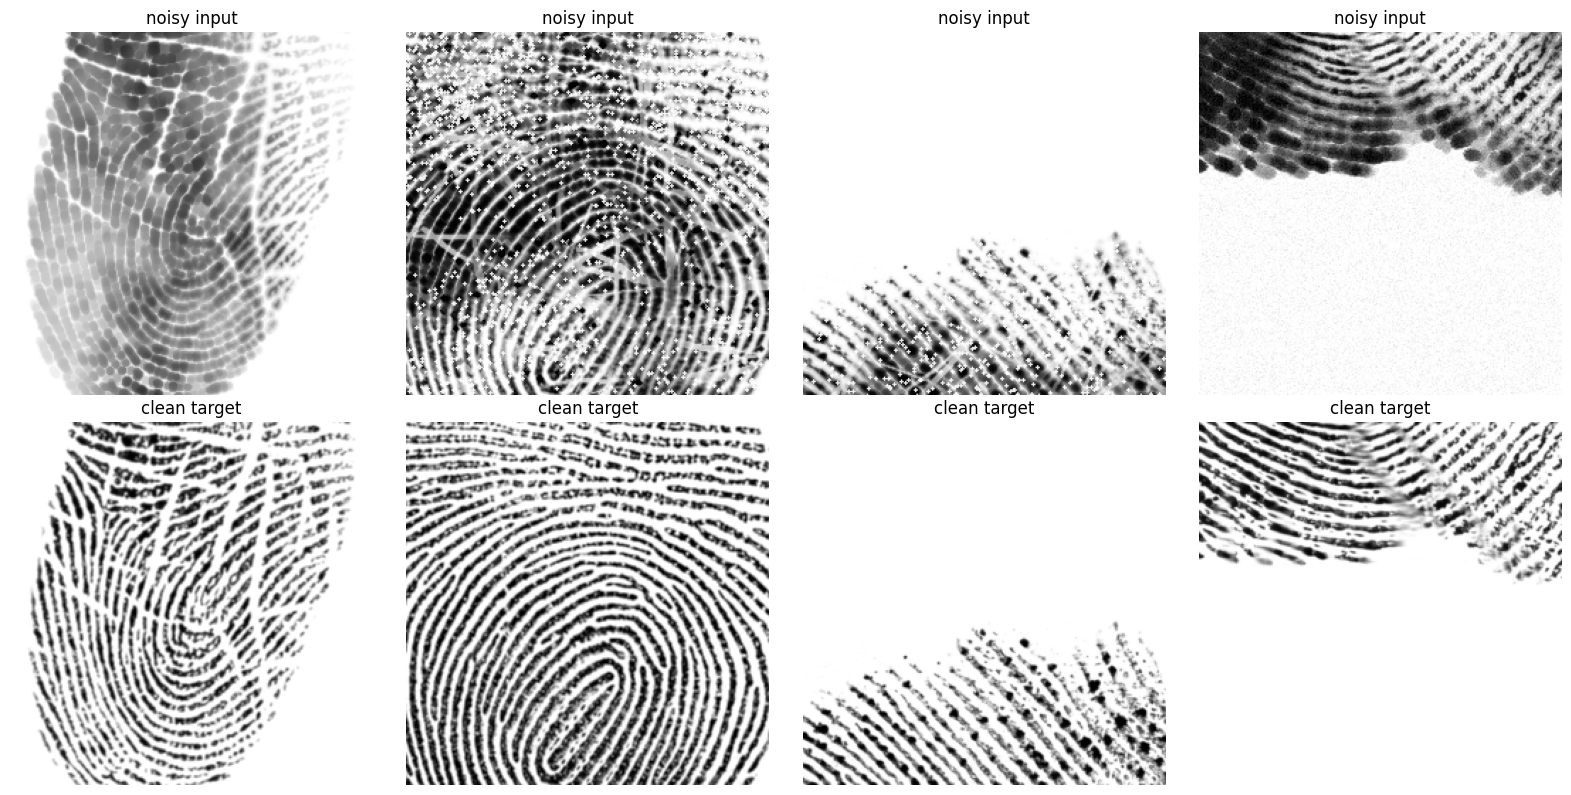

In [7]:
# ===== CELL 2: load images into RAM + paired random crops =====
def load_gray(p):
    return np.asarray(Image.open(p).convert('L'))

IMGS = {}                                                   # key -> (noisy uint8, clean uint8); train + val only
for _, r in tqdm(df[df.split.isin(['train', 'val'])].iterrows(), total=int(df.split.isin(['train', 'val']).sum()), desc='loading'):
    IMGS[r.key] = (load_gray(r.noisy), load_gray(r.clean))
print('cached:', len(IMGS), 'pairs | approx RAM GB:', round(sum(a.nbytes + b.nbytes for a, b in IMGS.values()) / 1e9, 2))

class PairCrops(Dataset):
    """random paired crops. train: random crop + flips, retries so the crop contains ink. val: fixed crop per image"""
    def __init__(self, frame, crop, train, repeat=1):
        self.keys = list(frame.key); self.crop = crop; self.train = train; self.repeat = repeat if train else 1
    def __len__(self): return len(self.keys) * self.repeat
    def __getitem__(self, i):
        key = self.keys[i % len(self.keys)]
        x, y = IMGS[key]
        c = self.crop
        H, W = x.shape
        if H < c or W < c:                                   # pad small images with white
            ph, pw = max(c - H, 0), max(c - W, 0)
            x = np.pad(x, ((0, ph), (0, pw)), constant_values=255); y = np.pad(y, ((0, ph), (0, pw)), constant_values=255)
            H, W = x.shape
        rng = np.random if self.train else np.random.RandomState(i)
        for _ in range(8):
            t, l = rng.randint(0, H - c + 1), rng.randint(0, W - c + 1)
            yc = y[t:t + c, l:l + c]
            if (yc < 128).mean() > 0.05: break               # crop has enough ink
        xc = x[t:t + c, l:l + c]
        if self.train:
            if np.random.rand() < 0.5: xc, yc = xc[:, ::-1], yc[:, ::-1]
            if np.random.rand() < 0.5: xc, yc = xc[::-1], yc[::-1]
        f = lambda a: torch.from_numpy(np.ascontiguousarray(a)).float().div(127.5).sub(1).unsqueeze(0)   # [-1, 1]
        return f(xc), f(yc)

dl_tr = DataLoader(PairCrops(df[df.split == 'train'], CFG['crop'], True, CFG['repeat']), batch_size=CFG['bs'],
                   shuffle=True, num_workers=CFG['workers'], drop_last=True, pin_memory=True, persistent_workers=CFG['workers'] > 0)
dl_va = DataLoader(PairCrops(df[df.split == 'val'], CFG['crop'], False), batch_size=CFG['bs'],
                   shuffle=False, num_workers=CFG['workers'])
print('train steps/epoch:', len(dl_tr), '| val batches:', len(dl_va))
xb, yb = next(iter(dl_tr)); print('batch:', tuple(xb.shape), float(xb.min()), float(xb.max()))
fig, ax = plt.subplots(2, 4, figsize=(16, 8))
for j in range(4):
    ax[0, j].imshow(xb[j, 0], cmap='gray', vmin=-1, vmax=1); ax[0, j].set_title('noisy input')
    ax[1, j].imshow(yb[j, 0], cmap='gray', vmin=-1, vmax=1); ax[1, j].set_title('clean target')
for a in ax.ravel(): a.axis('off')
plt.tight_layout(); plt.show()

In [9]:
# ===== CELL 3: generator (dilated SegNet), discriminator (PatchGAN), losses =====
def cbr(cin, cout, d=1):
    return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=d, dilation=d, bias=False), nn.BatchNorm2d(cout), nn.ReLU(True))

class DilatedSegNet(nn.Module):
    """5 encoder blocks (2 convs each, dilation 1,1,2,2,4,4,8,8,16,16) + max-pool indices, mirrored decoder with max-unpool,
    final 3x3 conv (1 filter) + Tanh. Input size must be a multiple of 32."""
    def __init__(self, ch=64):
        super().__init__()
        dil = [1, 2, 4, 8, 16]
        self.enc = nn.ModuleList([nn.Sequential(cbr(1 if i == 0 else ch, ch, dil[i]), cbr(ch, ch, dil[i])) for i in range(5)])
        self.dec = nn.ModuleList([nn.Sequential(cbr(ch, ch), cbr(ch, ch)) for _ in range(5)])
        self.pool = nn.MaxPool2d(2, 2, return_indices=True)
        self.unpool = nn.MaxUnpool2d(2, 2)
        self.out = nn.Sequential(nn.Conv2d(ch, 1, 3, padding=1), nn.Tanh())
    def forward(self, x):
        idxs, sizes = [], []
        for e in self.enc:
            x = e(x); sizes.append(x.size())
            x, i = self.pool(x); idxs.append(i)
        for k in range(4, -1, -1):
            x = self.unpool(x, idxs[k], output_size=sizes[k])
            x = self.dec[4 - k](x)
        return self.out(x)

class PatchD(nn.Module):
    """input = concat(noisy, clean-or-enhanced) -> patch map of real/fake logits. 4x4 convs, 64-128-256-512 stride 2, final 1 filter stride 1"""
    def __init__(self):
        super().__init__()
        L, cin = [], 2
        for cout in (64, 128, 256, 512):
            L += [nn.Conv2d(cin, cout, 4, 2, 1, bias=False), nn.BatchNorm2d(cout), nn.LeakyReLU(0.2, True)]; cin = cout
        L += [nn.Conv2d(512, 1, 4, 1, 1)]
        self.net = nn.Sequential(*L)
    def forward(self, x, y): return self.net(torch.cat([x, y], 1))

def init_w(m):
    if isinstance(m, (nn.Conv2d, nn.BatchNorm2d)) and hasattr(m, 'weight') and m.weight is not None:
        nn.init.normal_(m.weight, 1.0 if isinstance(m, nn.BatchNorm2d) else 0.0, 0.02)
        if getattr(m, 'bias', None) is not None: nn.init.zeros_(m.bias)

def log_kernel(sigma=1.0, size=7):
    """Laplacian of Gaussian, zero-sum (paper Eq. 2 uses the LoG operator to compare ridge edges)"""
    ax = torch.arange(size, dtype=torch.float32) - size // 2
    xx, yy = torch.meshgrid(ax, ax, indexing='ij'); r2 = xx ** 2 + yy ** 2
    k = (r2 - 2 * sigma ** 2) / sigma ** 4 * torch.exp(-r2 / (2 * sigma ** 2))
    return (k - k.mean())[None, None]

class Losses(nn.Module):
    def __init__(self):
        super().__init__()
        self.register_buffer('K', log_kernel())
        self.bce = nn.BCEWithLogitsLoss()
    def edge(self, fake, real):                              # sqrt(||LoG(F(x)) - LoG(y)||^2 + eps^2), mean over batch
        d = F.conv2d(fake.float(), self.K, padding=3) - F.conv2d(real.float(), self.K, padding=3)
        return torch.sqrt((d ** 2).flatten(1).sum(1) + CFG['eps'] ** 2).mean()

G = DilatedSegNet().to(DEV); D = PatchD().to(DEV); LS = Losses().to(DEV)
G.apply(init_w); D.apply(init_w)
print('G params (M):', round(sum(p.numel() for p in G.parameters()) / 1e6, 2), '| D params (M):', round(sum(p.numel() for p in D.parameters()) / 1e6, 2))
with torch.no_grad():
    t = torch.zeros(2, 1, 256, 256, device=DEV)
    print('G out:', tuple(G(t).shape), '| D out:', tuple(D(t, t).shape), '| odd-size check:', tuple(G(torch.zeros(1, 1, 96, 160, device=DEV)).shape))

G params (M): 0.7 | D params (M): 2.76
G out: (2, 1, 256, 256) | D out: (2, 1, 15, 15) | odd-size check: (1, 1, 96, 160)


In [10]:
# ===== CELL 4: training (resumable, saves last + best every epoch) =====
optG = torch.optim.Adam(G.parameters(), lr=CFG['lr'], betas=(CFG['beta1'], CFG['beta2']))
optD = torch.optim.Adam(D.parameters(), lr=CFG['lr'], betas=(CFG['beta1'], CFG['beta2']))
scG = torch.amp.GradScaler('cuda', enabled=CFG['amp'] and DEV.type == 'cuda')
scD = torch.amp.GradScaler('cuda', enabled=CFG['amp'] and DEV.type == 'cuda')
AMP = dict(device_type='cuda', dtype=torch.float16, enabled=CFG['amp'] and DEV.type == 'cuda')

LAST, BEST, LOG = OUT / 'ckpt' / 'last.pt', OUT / 'ckpt' / 'best_G.pt', OUT / 'results' / 'train_log.csv'
start_ep, best_l1, hist = 0, 1e9, []
RESUME = True
if RESUME and LAST.exists():
    ck = torch.load(LAST, map_location=DEV)
    G.load_state_dict(ck['G']); D.load_state_dict(ck['D']); optG.load_state_dict(ck['optG']); optD.load_state_dict(ck['optD'])
    start_ep, best_l1, hist = ck['epoch'] + 1, ck['best_l1'], ck['hist']
    print(f'resumed from epoch {start_ep}, best val L1 {best_l1:.4f}')

@torch.no_grad()
def validate():
    G.eval(); l1s, mses = [], []
    for x, y in dl_va:
        x, y = x.to(DEV), y.to(DEV)
        with torch.autocast(**AMP): p = G(x)
        p = p.float()
        l1s.append((p - y).abs().mean().item() / 2)                      # in [0,1] units
        mses.append((((p - y) / 2 * 255) ** 2).mean().item())
    G.train()
    return float(np.mean(l1s)), float(10 * np.log10(255 ** 2 / np.mean(mses)))

t0 = time.time()
for ep in range(start_ep, CFG['epochs']):
    G.train(); D.train(); agg = np.zeros(5); n = 0
    pbar = tqdm(dl_tr, desc=f'ep {ep + 1}/{CFG["epochs"]}', leave=False)
    for x, y in pbar:
        x, y = x.to(DEV, non_blocking=True), y.to(DEV, non_blocking=True)
        # ---- discriminator: real pair (x, y) vs fake pair (x, G(x)) ----
        with torch.autocast(**AMP):
            fake = G(x)
            dr, df_ = D(x, y), D(x, fake.detach())
            lD = 0.5 * (LS.bce(dr, torch.ones_like(dr)) + LS.bce(df_, torch.zeros_like(df_)))
        optD.zero_grad(set_to_none=True); scD.scale(lD).backward(); scD.step(optD); scD.update()
        # ---- generator: fool D + L1 + edge loss ----
        with torch.autocast(**AMP):
            dg = D(x, fake)
            adv = LS.bce(dg, torch.ones_like(dg))
        l1 = F.l1_loss(fake.float(), y.float()); ed = LS.edge(fake, y)
        lG = adv.float() + CFG['mu'] * l1 + CFG['lam'] * ed
        optG.zero_grad(set_to_none=True); scG.scale(lG).backward(); scG.step(optG); scG.update()
        agg += np.array([lD.item(), adv.item(), l1.item(), ed.item(), lG.item()]); n += 1
        pbar.set_postfix(D=f'{lD.item():.3f}', adv=f'{adv.item():.3f}', L1=f'{l1.item():.3f}')
    agg /= max(n, 1)
    v_l1, v_psnr = validate()
    row = dict(epoch=ep + 1, lossD=agg[0], adv=agg[1], L1=agg[2], edge=agg[3], lossG=agg[4], val_L1=v_l1, val_PSNR=v_psnr, min=(time.time() - t0) / 60)
    hist.append(row)
    if v_l1 < best_l1:
        best_l1 = v_l1; torch.save(G.state_dict(), BEST)
    torch.save(dict(G=G.state_dict(), D=D.state_dict(), optG=optG.state_dict(), optD=optD.state_dict(),
                    epoch=ep, best_l1=best_l1, hist=hist), LAST)
    pd.DataFrame(hist).to_csv(LOG, index=False)
    print(f"ep {ep + 1:3d} | D {agg[0]:.3f} adv {agg[1]:.3f} L1 {agg[2]:.4f} edge {agg[3]:.2f} | val L1 {v_l1:.4f} PSNR {v_psnr:.2f} | best {best_l1:.4f} | {row['min']:.1f} min")
    if (time.time() - t0) / 3600 > CFG['time_limit_h']:
        print('time limit reached, stopping cleanly; run this cell again to resume'); break

ep 1/60:   0%|          | 0/330 [00:00<?, ?it/s]

ep   1 | D 0.564 adv 1.266 L1 0.3182 edge 293.42 | val L1 0.1413 PSNR 12.85 | best 0.1413 | 1.2 min


ep 2/60:   0%|          | 0/330 [00:00<?, ?it/s]

ep   2 | D 0.438 adv 1.650 L1 0.2666 edge 274.65 | val L1 0.1276 PSNR 13.28 | best 0.1276 | 2.6 min


ep 3/60:   0%|          | 0/330 [00:00<?, ?it/s]

ep   3 | D 0.409 adv 1.707 L1 0.2523 edge 272.03 | val L1 0.1373 PSNR 13.21 | best 0.1276 | 3.9 min


... (110 outputs left out)

ep 59/60:   0%|          | 0/330 [00:00<?, ?it/s]

ep  59 | D 0.395 adv 1.880 L1 0.1626 edge 209.83 | val L1 0.0829 PSNR 16.49 | best 0.0801 | 78.3 min


ep 60/60:   0%|          | 0/330 [00:00<?, ?it/s]

ep  60 | D 0.381 adv 1.917 L1 0.1633 edge 210.25 | val L1 0.0814 PSNR 16.71 | best 0.0801 | 79.6 min


In [11]:
# ===== CELL 5: enhance the 338 test images (full size, best checkpoint) =====
G.load_state_dict(torch.load(BEST, map_location=DEV)); G.eval()
te = df[df.split == 'test'].reset_index(drop=True)
rows = []
for _, r in tqdm(te.iterrows(), total=len(te), desc='enhancing test'):
    t_all = time.time()
    x = load_gray(r.noisy); H, W = x.shape
    ph, pw = (-H) % 32, (-W) % 32                                        # SegNet needs multiples of 32
    xp = np.pad(x, ((0, ph), (0, pw)), constant_values=255)
    xt = torch.from_numpy(xp).float().div(127.5).sub(1)[None, None].to(DEV)
    if DEV.type == 'cuda': torch.cuda.synchronize()
    t_m = time.time()
    with torch.no_grad(), torch.autocast(**AMP): p = G(xt)
    if DEV.type == 'cuda': torch.cuda.synchronize()
    t_model = time.time() - t_m
    out = ((p.float()[0, 0, :H, :W].cpu().numpy() + 1) * 127.5).clip(0, 255).round().astype(np.uint8)
    dst = OUT / 'enhanced_test' / r.device / f'{r.key}.png'; dst.parent.mkdir(exist_ok=True)
    Image.fromarray(out).save(dst, dpi=(500, 500))                       # 500 PPI in the header, NFIQ2 needs it
    rows.append(dict(key=r.key, test_time=t_model, comp_time=time.time() - t_all))
tm = pd.DataFrame(rows)
print(f"done: {len(tm)} images | test time {tm.test_time.mean():.3f} s/img | computation time {tm.comp_time.mean():.3f} s/img")
tm.to_csv(OUT / 'results' / 'test_times.csv', index=False)

enhancing test:   0%|          | 0/338 [00:00<?, ?it/s]

done: 338 images | test time 0.021 s/img | computation time 0.045 s/img


In [12]:
# ===== CELL 6: SSIM, PSNR, RMSE (noisy vs clean  ->  enhanced vs clean), per device and per severity band =====
from skimage.metrics import structural_similarity as ssim_fn, peak_signal_noise_ratio as psnr_fn

def band(s):
    return 'severe 0-10' if s <= 10 else 'heavy 11-30' if s <= 30 else 'medium 31-55' if s <= 55 else 'barely noisy 56+'

rows = []
for _, r in tqdm(te.iterrows(), total=len(te), desc='metrics'):
    c = load_gray(r.clean); n = load_gray(r.noisy)
    e = np.asarray(Image.open(OUT / 'enhanced_test' / r.device / f'{r.key}.png').convert('L'))
    row = dict(key=r.key, device=r.device, noisy_nfiq2=r.noisy_nfiq2, clean_nfiq2=r.clean_nfiq2, noises=r.noises, band=band(r.noisy_nfiq2))
    for tag, a in (('noisy', n), ('enh', e)):
        row[f'ssim_{tag}'] = ssim_fn(c, a, data_range=255)
        row[f'psnr_{tag}'] = psnr_fn(c, a, data_range=255)
        row[f'rmse_{tag}'] = float(np.sqrt(((c.astype(np.float64) - a) ** 2).mean()))
    rows.append(row)
M = pd.DataFrame(rows).merge(tm, on='key')
M.to_csv(OUT / 'results' / 'test_all_metrics.csv', index=False)

def rng_(col): return f"{M[col].mean():.3f}"
print(f"TEST pairs: {len(M)}   (noisy -> enhanced, mean)")
print(f"SSIM  {rng_('ssim_noisy')} -> {rng_('ssim_enh')}   | PSNR {rng_('psnr_noisy')} -> {rng_('psnr_enh')} dB   | RMSE {rng_('rmse_noisy')} -> {rng_('rmse_enh')}")
print(f"SSIM range enhanced {M.ssim_enh.min():.3f} to {M.ssim_enh.max():.3f} | PSNR range {M.psnr_enh.min():.2f} to {M.psnr_enh.max():.2f}")
print(f"time: test {M.test_time.mean():.3f} s | computation {M.comp_time.mean():.3f} s per image")
cols = ['ssim_noisy', 'ssim_enh', 'psnr_noisy', 'psnr_enh', 'rmse_noisy', 'rmse_enh']
print('\nper device:\n', M.groupby('device')[cols].mean().round(3).assign(n=M.groupby('device').size()).to_string())
print('\nper severity band (by noisy NFIQ2):\n', M.groupby('band')[cols].mean().round(3).assign(n=M.groupby('band').size()).to_string())
print('\nper noise type (images that contain it):')
exp = M.assign(noise=M.noises.str.split('+')).explode('noise')
print(exp.groupby('noise')[['ssim_noisy', 'ssim_enh', 'psnr_enh']].mean().round(3).assign(n=exp.groupby('noise').size()).sort_values('ssim_enh').to_string())

metrics:   0%|          | 0/338 [00:00<?, ?it/s]

TEST pairs: 338   (noisy -> enhanced, mean)
SSIM  0.672 -> 0.818   | PSNR 13.288 -> 17.812 dB   | RMSE 57.600 -> 34.316
SSIM range enhanced 0.424 to 0.987 | PSNR range 11.20 to 27.96
time: test 0.021 s | computation 0.045 s per image

per device:
         ssim_noisy  ssim_enh  psnr_noisy  psnr_enh  rmse_noisy  rmse_enh    n
device                                                                       
R            0.558     0.827      11.091    16.637      72.445    38.673   60
S            0.586     0.843      11.906    17.613      66.689    34.668   93
U            0.766     0.821      14.728    18.548      48.003    31.766  104
V            0.732     0.780      14.652    17.966      48.489    33.958   81

per severity band (by noisy NFIQ2):
               ssim_noisy  ssim_enh  psnr_noisy  psnr_enh  rmse_noisy  rmse_enh    n
band                                                                               
heavy 11-30        0.684     0.827      13.052    17.743      59.418    34.393

In [13]:
# ===== CELL 7: NFIQ2 of the enhanced test images (noisy + clean NFIQ2 are already in the metadata) =====
import subprocess, sys
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'nbis-python'])
import nbis
ext = nbis.new_nbis_extractor(nbis.NbisExtractorSettings(min_quality=0.0, get_center=False, check_fingerprint=False, compute_nfiq2=True, ppi=500.0))

def nfiq2_file(p):
    try: return int(ext.extract_minutiae(Path(p).read_bytes()).quality().score)
    except Exception: return np.nan

M['nfiq2_enh'] = [nfiq2_file(OUT / 'enhanced_test' / r.device / f'{r.key}.png') for _, r in tqdm(M.iterrows(), total=len(M), desc='NFIQ2')]
M.to_csv(OUT / 'results' / 'test_all_metrics.csv', index=False)
ok = M.dropna(subset=['nfiq2_enh'])
print(f"scored {len(ok)}/{len(M)} | NFIQ2 mean: noisy {ok.noisy_nfiq2.mean():.2f} -> enhanced {ok.nfiq2_enh.mean():.2f} | clean reference {ok.clean_nfiq2.mean():.2f}")
print(f"improved {(ok.nfiq2_enh > ok.noisy_nfiq2).sum()}/{len(ok)} | worse {(ok.nfiq2_enh < ok.noisy_nfiq2).sum()}")
print('\nper severity band:'); print(ok.groupby('band')[['noisy_nfiq2', 'nfiq2_enh', 'clean_nfiq2']].mean().round(1).assign(n=ok.groupby('band').size()).to_string())
print('\nper device:'); print(ok.groupby('device')[['noisy_nfiq2', 'nfiq2_enh', 'clean_nfiq2']].mean().round(1).to_string())

NFIQ2:   0%|          | 0/338 [00:00<?, ?it/s]

scored 338/338 | NFIQ2 mean: noisy 20.08 -> enhanced 63.23 | clean reference 71.77
improved 327/338 | worse 11

per severity band:
              noisy_nfiq2  nfiq2_enh  clean_nfiq2    n
band                                                  
heavy 11-30          20.4       63.2         70.6  114
medium 31-55         44.3       66.5         74.1   84
severe 0-10           5.3       61.3         71.3  140

per device:
        noisy_nfiq2  nfiq2_enh  clean_nfiq2
device                                     
R              16.4       67.4         73.3
S              20.2       71.2         73.2
U              18.9       58.6         70.4
V              24.2       57.0         70.8


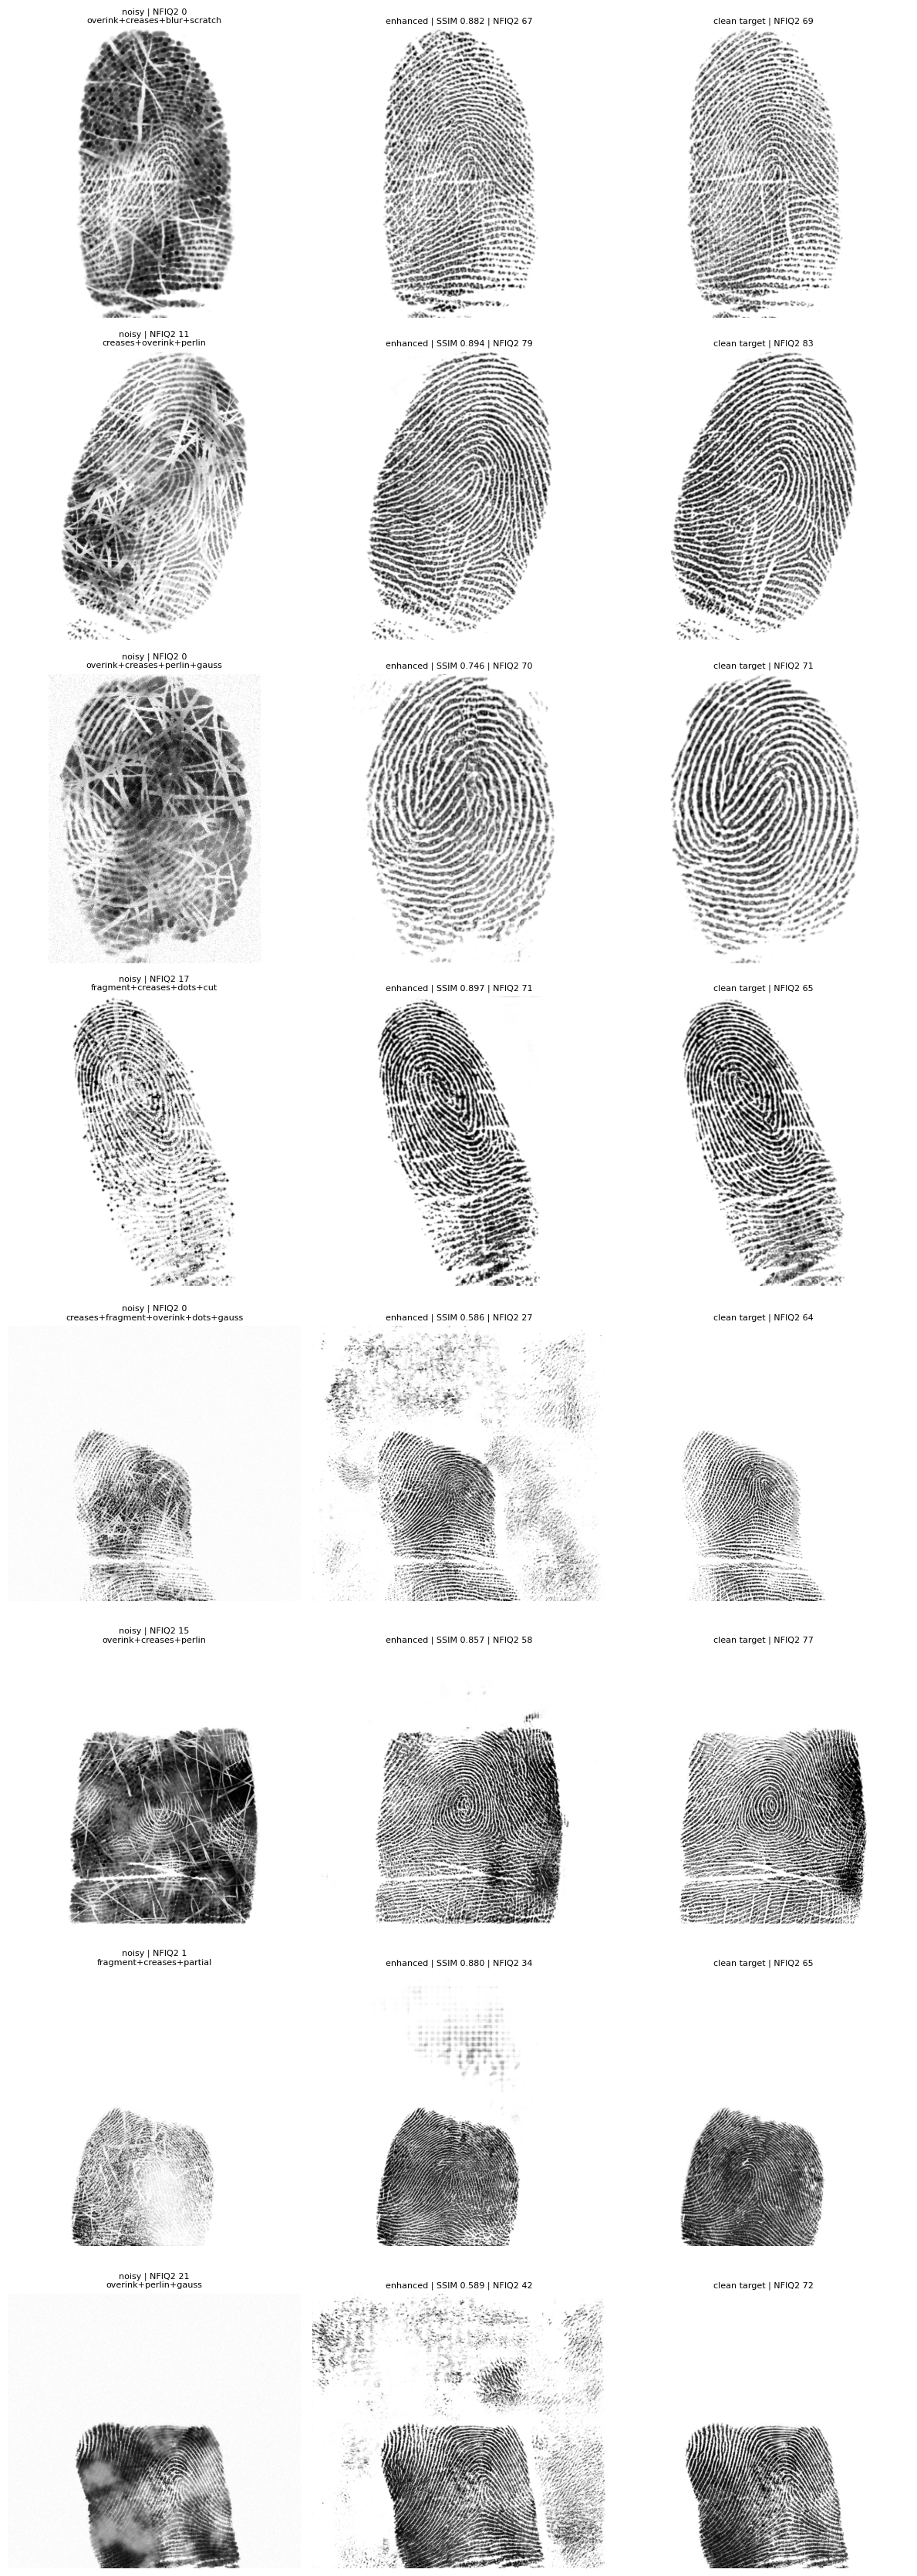

In [14]:
# ===== CELL 8: before / after sheet (noisy | enhanced | clean), 2 per device, spread across severity =====
pick = pd.concat([g.sort_values('noisy_nfiq2').iloc[[0, len(g) // 2]] for _, g in M.groupby('device')])
fig, ax = plt.subplots(len(pick), 3, figsize=(12, 4.2 * len(pick)))
for i, (_, r) in enumerate(pick.iterrows()):
    e = Image.open(OUT / 'enhanced_test' / r.device / f'{r.key}.png')
    ttl = [f"noisy | NFIQ2 {r.noisy_nfiq2:.0f}\n{r.noises}",
           f"enhanced | SSIM {r.ssim_enh:.3f}" + (f" | NFIQ2 {r.nfiq2_enh:.0f}" if 'nfiq2_enh' in M else ''),
           f"clean target | NFIQ2 {r.clean_nfiq2:.0f}"]
    for j, im in enumerate((Image.open(df.set_index('key').loc[r.key, 'noisy']), e, Image.open(df.set_index('key').loc[r.key, 'clean']))):
        ax[i, j].imshow(im, cmap='gray'); ax[i, j].set_title(ttl[j], fontsize=8); ax[i, j].axis('off')
plt.tight_layout(); plt.savefig(OUT / 'visual' / 'before_after.png', dpi=110); plt.show()

#1 00002434_S_500_slap_06 | device S | enhanced NFIQ2 92
#2 00002611_S_500_slap_06 | device S | enhanced NFIQ2 92
#3 00002516_S_500_slap_01 | device S | enhanced NFIQ2 91


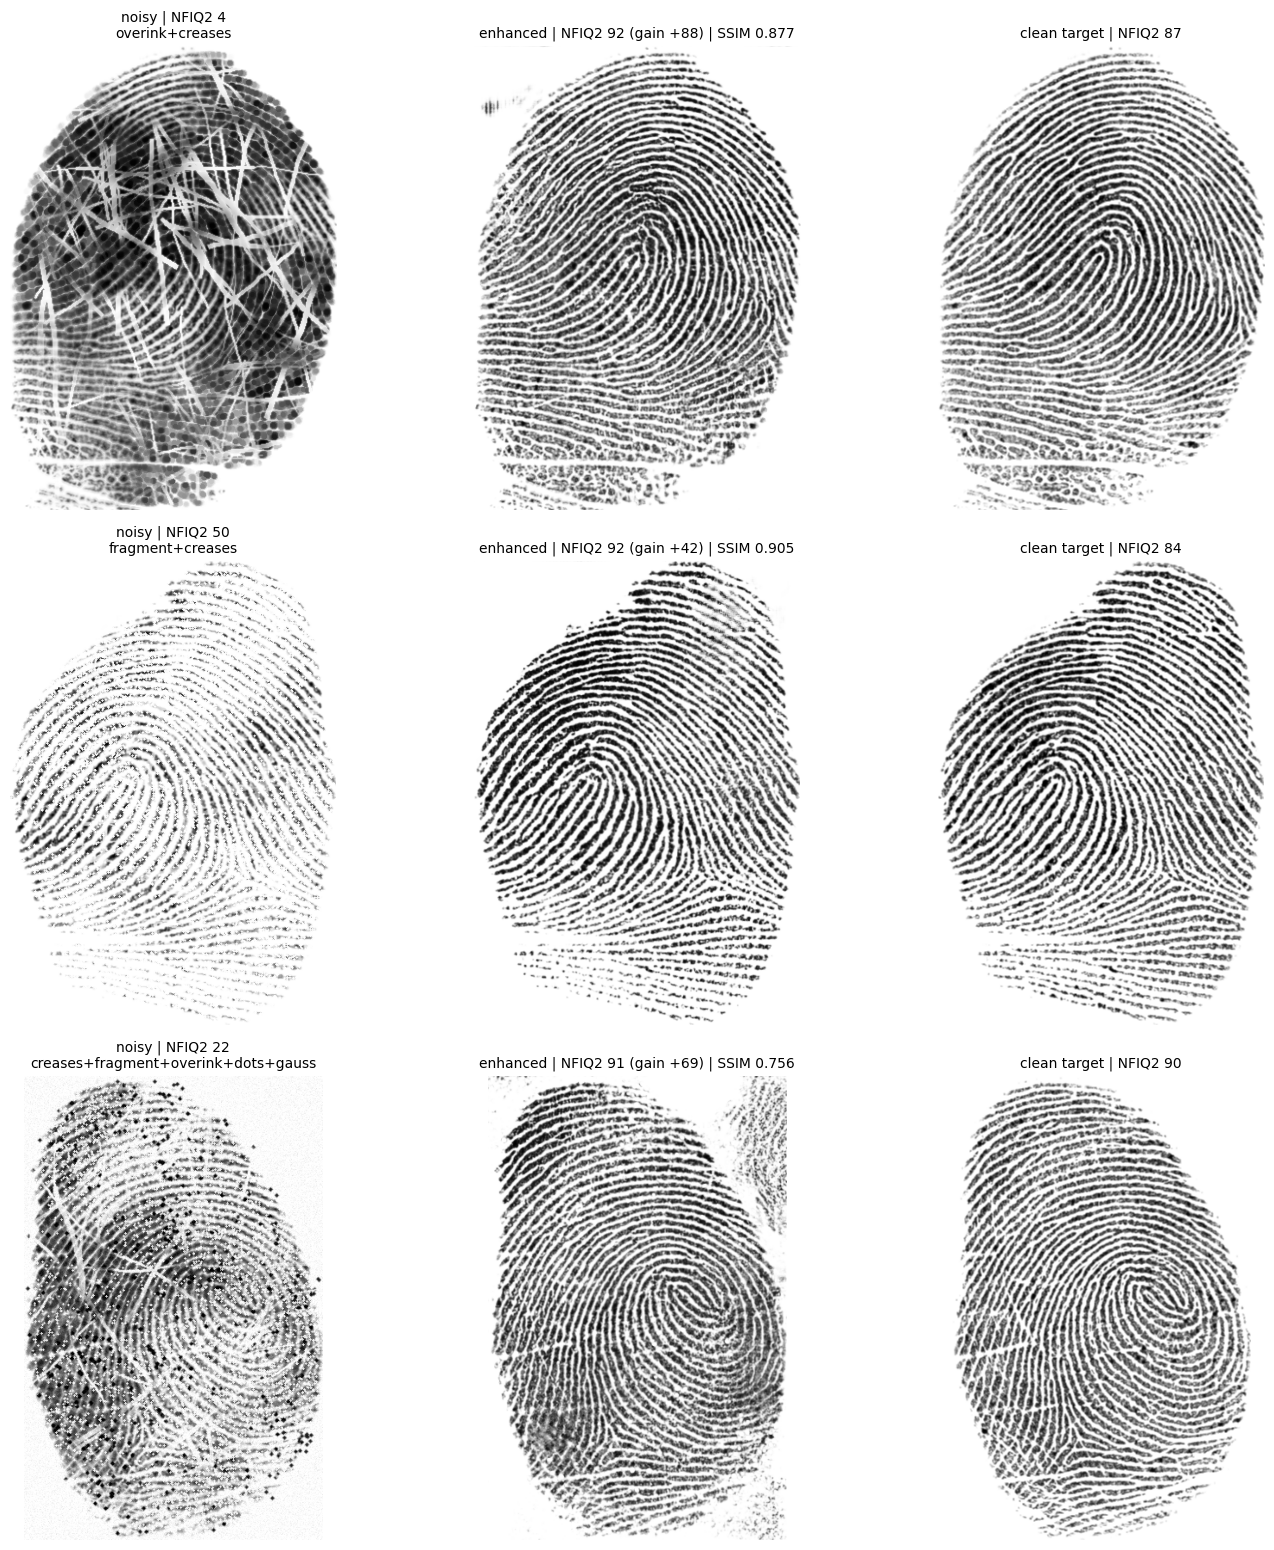

In [15]:
# ===== CELL 9: top-3 images by NFIQ2 (noisy | enhanced | clean) =====
BY = 'nfiq2_enh'          # 'nfiq2_enh' = highest enhanced NFIQ2 score; use 'gain' for the biggest improvement, 'ssim_enh' for best SSIM
N  = 3
M['gain'] = M['nfiq2_enh'] - M['noisy_nfiq2']
top = M.sort_values(BY, ascending=False).head(N)
pth = df.set_index('key')
fig, ax = plt.subplots(N, 3, figsize=(15, 5.2 * N))
for i, (_, r) in enumerate(top.iterrows()):
    ims = (Image.open(pth.loc[r.key, 'noisy']), Image.open(OUT / 'enhanced_test' / r.device / f'{r.key}.png'), Image.open(pth.loc[r.key, 'clean']))
    ttl = (f"noisy | NFIQ2 {r.noisy_nfiq2:.0f}\n{r.noises}",
           f"enhanced | NFIQ2 {r.nfiq2_enh:.0f} (gain {r.gain:+.0f}) | SSIM {r.ssim_enh:.3f}",
           f"clean target | NFIQ2 {r.clean_nfiq2:.0f}")
    for j in range(3):
        ax[i, j].imshow(ims[j], cmap='gray'); ax[i, j].set_title(ttl[j], fontsize=10); ax[i, j].axis('off')
    print(f"#{i + 1} {r.key} | device {r.device} | enhanced NFIQ2 {r.nfiq2_enh:.0f}")
plt.tight_layout(); plt.savefig(OUT / 'visual' / f'top{N}_{BY}.png', dpi=110); plt.show()

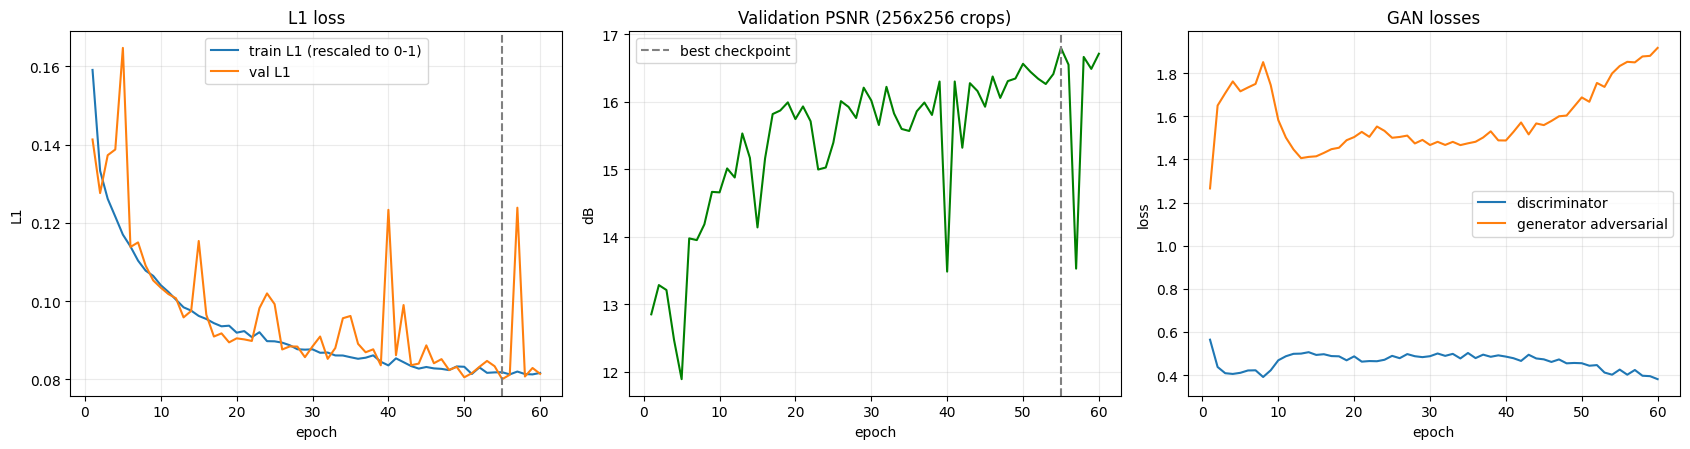

FQEI = 0.5900  (Es 710, Ds -5, IS 1154, WS -198)


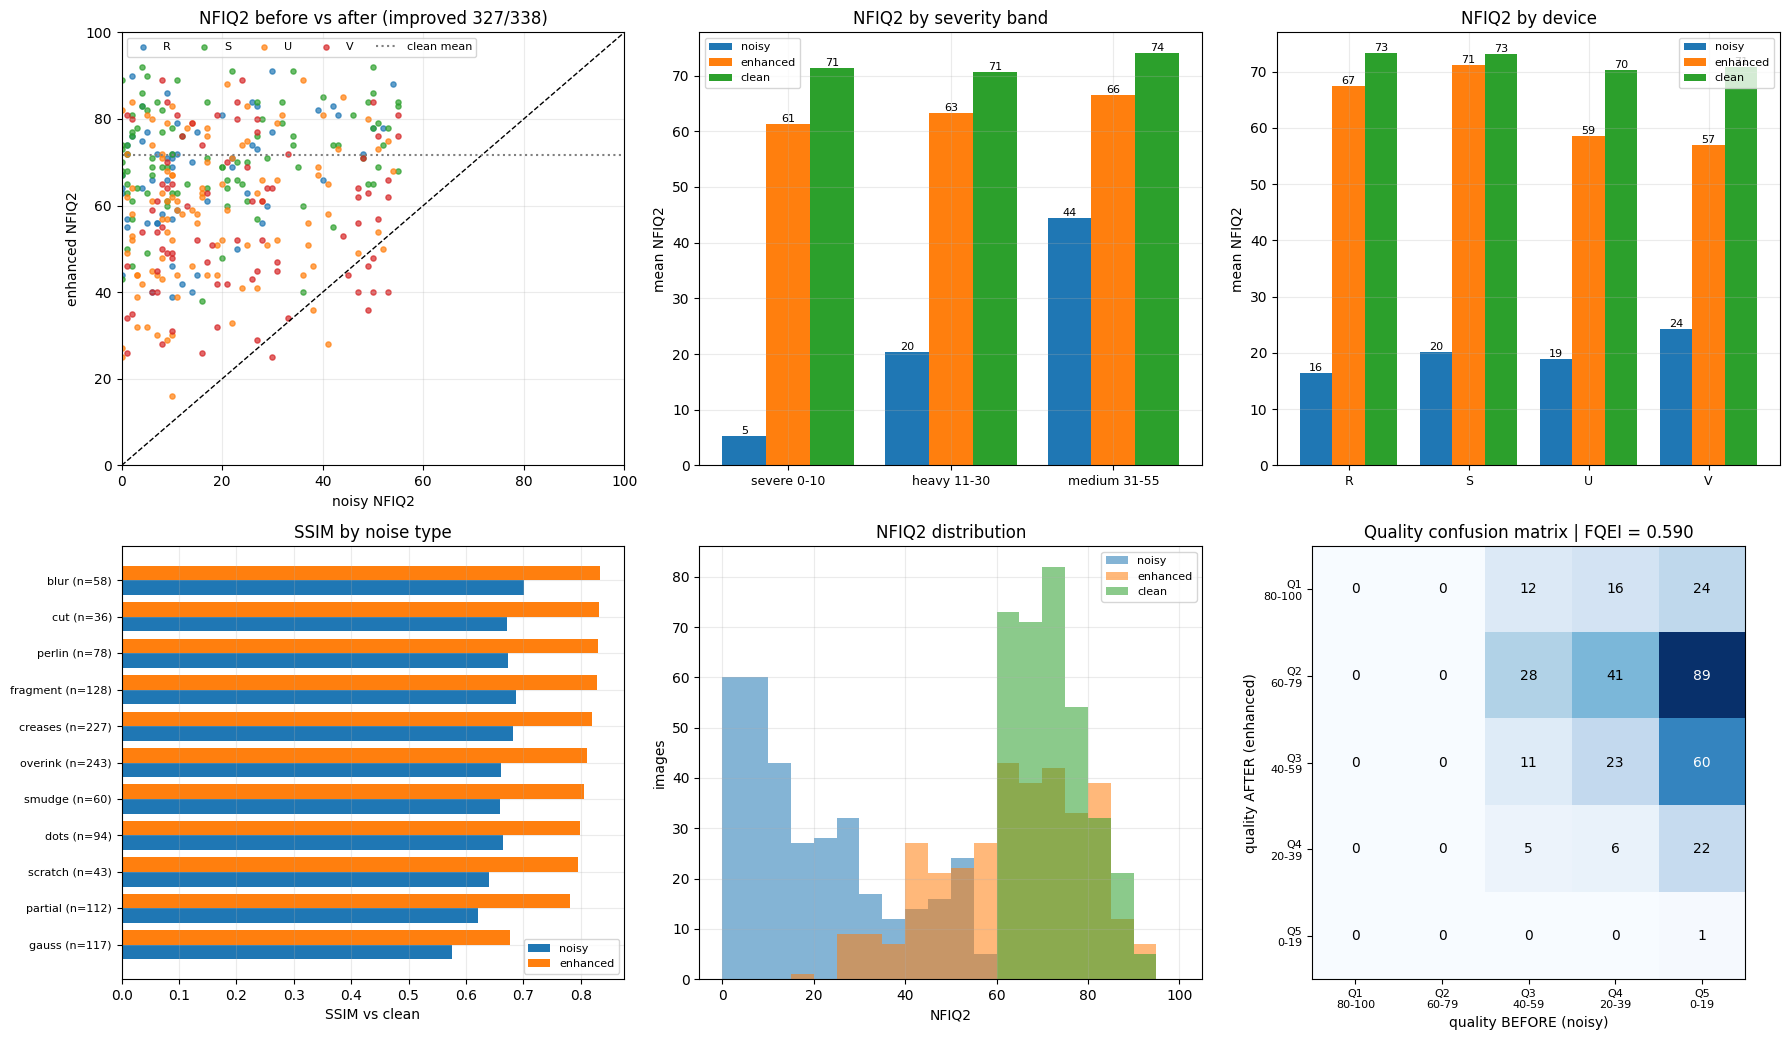

saved: /kaggle/working/cgan_v2/visual/fig1_training.png | /kaggle/working/cgan_v2/visual/fig2_test_results.png


In [17]:
# ===== CELL 10: graphs (training curves + test results), saved as PNG for the thesis =====
# reads the CSVs from disk, so it also works after a restart (run Cells 1 and 6/7 only if test_all_metrics.csv has no nfiq2_enh)
H = pd.read_csv(OUT / 'results' / 'train_log.csv')
T = pd.read_csv(OUT / 'results' / 'test_all_metrics.csv')
assert 'nfiq2_enh' in T, 'run Cell 7 (NFIQ2) first'
T = T.dropna(subset=['nfiq2_enh'])
DEVC = {'R': '#1f77b4', 'S': '#2ca02c', 'U': '#ff7f0e', 'V': '#d62728'}
ORDER_B = ['severe 0-10', 'heavy 11-30', 'medium 31-55', 'barely noisy 56+']
plt.rcParams.update({'font.size': 10, 'axes.grid': True, 'grid.alpha': 0.25})

# ---------- Figure 1: training curves ----------
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
ax[0].plot(H.epoch, H.L1 / 2, label='train L1 (rescaled to 0-1)'); ax[0].plot(H.epoch, H.val_L1, label='val L1')
ax[0].axvline(H.epoch[H.val_L1.idxmin()], ls='--', c='gray'); ax[0].set(xlabel='epoch', ylabel='L1', title='L1 loss'); ax[0].legend()
ax[1].plot(H.epoch, H.val_PSNR, c='green'); ax[1].axvline(H.epoch[H.val_L1.idxmin()], ls='--', c='gray', label='best checkpoint')
ax[1].set(xlabel='epoch', ylabel='dB', title='Validation PSNR (256x256 crops)'); ax[1].legend()
ax[2].plot(H.epoch, H.lossD, label='discriminator'); ax[2].plot(H.epoch, H.adv, label='generator adversarial')
ax[2].set(xlabel='epoch', ylabel='loss', title='GAN losses'); ax[2].legend()
plt.tight_layout(); plt.savefig(OUT / 'visual' / 'fig1_training.png', dpi=200); plt.show()

# ---------- quality classes from NFIQ2 + FQEI (Alotaibi et al. Eq. 6-12, 5 equal NFIQ2 classes, Q1 = best) ----------
def qclass(s): return int(min(4, max(0, (100 - s) // 20))) + 1          # 80-100 -> 1 ... 0-19 -> 5
qb, qa = T.noisy_nfiq2.map(qclass).values, T.nfiq2_enh.map(qclass).values
QCM = np.zeros((5, 5), int)                                              # QCM[i, j]: before class j+1 -> after class i+1
for b, a in zip(qb, qa): QCM[a - 1, b - 1] += 1
W = np.array([[j - i for j in range(5)] for i in range(5)])             # weight quality matrix (+ up, - down)
Es = (QCM * W)[np.triu_indices(5, 1)].sum(); Ds = (QCM * W)[np.tril_indices(5, -1)].sum()
cnt = QCM.sum(0); IS = sum(cnt[j] * j for j in range(1, 5)); WS = -sum(cnt[j] * (4 - j) for j in range(4))
FQEI = Es / IS - (Ds / WS if WS else 0)
print(f'FQEI = {FQEI:.4f}  (Es {Es}, Ds {Ds}, IS {IS}, WS {WS})')

# ---------- Figure 2: test results ----------
fig, ax = plt.subplots(2, 3, figsize=(18, 10.5))
a = ax[0, 0]
for d, g in T.groupby('device'): a.scatter(g.noisy_nfiq2, g.nfiq2_enh, s=14, alpha=0.7, c=DEVC.get(d), label=d)
a.plot([0, 100], [0, 100], 'k--', lw=1); a.axhline(T.clean_nfiq2.mean(), c='gray', ls=':', label='clean mean')
a.set(xlabel='noisy NFIQ2', ylabel='enhanced NFIQ2', xlim=(0, 100), ylim=(0, 100), title=f'NFIQ2 before vs after (improved {(T.nfiq2_enh > T.noisy_nfiq2).sum()}/{len(T)})'); a.legend(ncol=5, fontsize=8)

def grouped(a, key, order, title):
    g = T.groupby(key)[['noisy_nfiq2', 'nfiq2_enh', 'clean_nfiq2']].mean().reindex(order).dropna(); x = np.arange(len(g)); w = 0.27
    for k, (c, lab) in enumerate(zip(['noisy_nfiq2', 'nfiq2_enh', 'clean_nfiq2'], ['noisy', 'enhanced', 'clean'])):
        b = a.bar(x + (k - 1) * w, g[c], w, label=lab); a.bar_label(b, fmt='%.0f', fontsize=8)
    a.set_xticks(x); a.set_xticklabels(g.index, fontsize=9); a.set(ylabel='mean NFIQ2', title=title); a.legend(fontsize=8)
grouped(ax[0, 1], 'band', ORDER_B, 'NFIQ2 by severity band')
grouped(ax[0, 2], 'device', ['R', 'S', 'U', 'V'], 'NFIQ2 by device')

a = ax[1, 0]
ex = T.assign(noise=T.noises.str.split('+')).explode('noise'); g = ex.groupby('noise')[['ssim_noisy', 'ssim_enh']].mean().sort_values('ssim_enh'); y = np.arange(len(g))
a.barh(y - 0.2, g.ssim_noisy, 0.4, label='noisy'); a.barh(y + 0.2, g.ssim_enh, 0.4, label='enhanced')
a.set_yticks(y); a.set_yticklabels([f'{n} (n={int((ex.noise == n).sum())})' for n in g.index], fontsize=8); a.set(xlabel='SSIM vs clean', title='SSIM by noise type'); a.legend(fontsize=8)

a = ax[1, 1]
bins = np.arange(0, 105, 5)
for col, lab in (('noisy_nfiq2', 'noisy'), ('nfiq2_enh', 'enhanced'), ('clean_nfiq2', 'clean')): a.hist(T[col], bins=bins, alpha=0.55, label=lab)
a.set(xlabel='NFIQ2', ylabel='images', title='NFIQ2 distribution'); a.legend(fontsize=8)

a = ax[1, 2]
im = a.imshow(QCM, cmap='Blues'); lab = ['Q1\n80-100', 'Q2\n60-79', 'Q3\n40-59', 'Q4\n20-39', 'Q5\n0-19']
a.set_xticks(range(5)); a.set_xticklabels(lab, fontsize=8); a.set_yticks(range(5)); a.set_yticklabels(lab, fontsize=8); a.grid(False)
for i in range(5):
    for j in range(5): a.text(j, i, QCM[i, j], ha='center', va='center', color='white' if QCM[i, j] > QCM.max() / 2 else 'black')
a.set(xlabel='quality BEFORE (noisy)', ylabel='quality AFTER (enhanced)', title=f'Quality confusion matrix | FQEI = {FQEI:.3f}')
plt.tight_layout(); plt.savefig(OUT / 'visual' / 'fig2_test_results.png', dpi=200); plt.show()
print('saved:', OUT / 'visual' / 'fig1_training.png', '|', OUT / 'visual' / 'fig2_test_results.png')

                  NFIQ2   SSIM    PSNR    RMSE  FUSED  FUSED_lo  FUSED_hi  win_rate
cGAN (Alotaibi)  63.234  0.818  17.812  34.316  0.632     0.621     0.642     100.0

share of random weightings where each model ranks #1 (%):
cGAN (Alotaibi)    100.0

fused score by severity band:
              cGAN (Alotaibi)
heavy 11-30             0.634
medium 31-55            0.652
severe 0-10             0.618


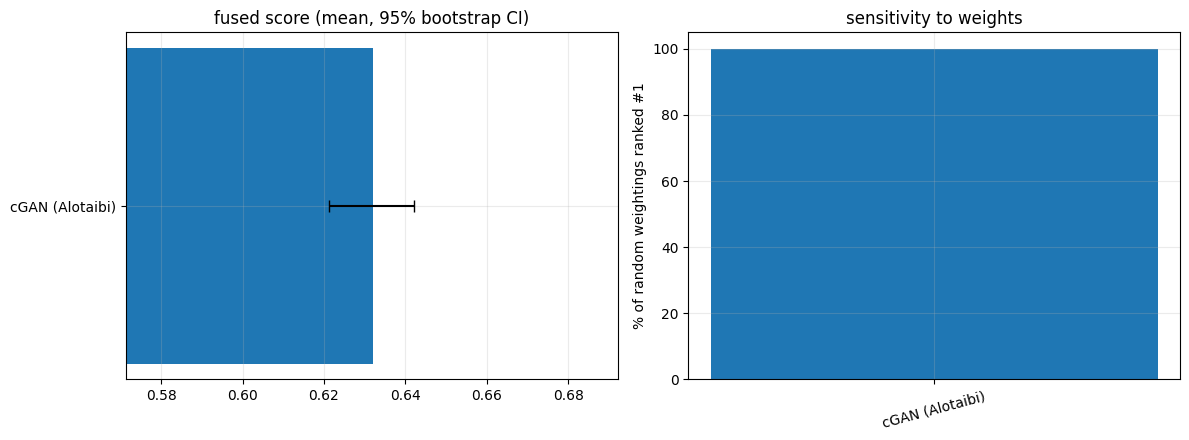

In [20]:
# ===== CELL 11: metric fusion -> which model to continue with =====
# Put one test_all_metrics.csv per model here. They must cover the SAME 338 test keys.
MODEL_CSVS= {

    'cGAN (Alotaibi)': '/kaggle/working/cgan_v2/results/test_all_metrics.csv',
}
# expected columns: key, ssim_enh, psnr_enh, rmse_enh, nfiq2_enh, noisy_nfiq2, clean_nfiq2. If a model's CSV uses other names:
RENAME = {   # e.g. 'Nested UNet': {'SSIM_enh': 'ssim_enh', 'NFIQ2_after': 'nfiq2_enh'}
}
W = dict(nfiq2=1 / 3, ssim=1 / 3, psnr=1 / 3)        # RMSE is NOT a separate term: PSNR = 20*log10(255/RMSE), same information
PSNR_CAP = 40.0                                       # dB value that counts as "perfect" for the 0-1 scale

R = {}
for name, path in MODEL_CSVS.items():
    t = pd.read_csv(path, dtype={'key': str}).rename(columns=RENAME.get(name, {})).set_index('key')
    miss = {'ssim_enh', 'psnr_enh', 'rmse_enh', 'nfiq2_enh', 'noisy_nfiq2', 'clean_nfiq2'} - set(t.columns)
    assert not miss, f'{name}: missing columns {miss}'
    R[name] = t
keys = sorted(set.intersection(*[set(t.index) for t in R.values()]))
assert len(keys) == len(next(iter(R.values()))), f'models do not cover the same test images ({len(keys)} in common)'
R = {n: t.loc[keys] for n, t in R.items()}; names = list(R)

# every component on a 0-1 scale, higher = better, with a FIXED scale (no min-max across models, that would blow up tiny gaps)
comp = {n: np.stack([np.clip(t.nfiq2_enh / 100, 0, 1), np.clip(t.ssim_enh, 0, 1), np.clip(t.psnr_enh / PSNR_CAP, 0, 1)], 1) for n, t in R.items()}
w = np.array([W['nfiq2'], W['ssim'], W['psnr']]); w = w / w.sum()
F = {n: comp[n] @ w for n in names}                                   # fused score per image
rng = np.random.RandomState(0); B = rng.randint(0, len(keys), (2000, len(keys)))

# 1) summary table
tab = pd.DataFrame({n: dict(NFIQ2=R[n].nfiq2_enh.mean(), SSIM=R[n].ssim_enh.mean(), PSNR=R[n].psnr_enh.mean(), RMSE=R[n].rmse_enh.mean(),
                            FUSED=F[n].mean(), FUSED_lo=np.percentile(F[n][B].mean(1), 2.5), FUSED_hi=np.percentile(F[n][B].mean(1), 97.5),
                            win_rate=0.0) for n in names}).T
best_per_img = np.argmax(np.stack([F[n] for n in names], 1), 1)
tab['win_rate'] = [100 * (best_per_img == i).mean() for i in range(len(names))]
print(tab.round(3).sort_values('FUSED', ascending=False).to_string())

# 2) is the gap real? paired bootstrap on the same images
top = tab.FUSED.idxmax()
for n in names:
    if n == top: continue
    d = (F[top] - F[n])[B].mean(1)
    print(f"{top} - {n}: {d.mean():+.4f}  95% CI [{np.percentile(d, 2.5):+.4f}, {np.percentile(d, 97.5):+.4f}]  -> {'clear winner' if np.percentile(d, 2.5) > 0 else 'NOT a clear difference'}")

# 3) does the winner depend on my weights? 5000 random weight vectors
Wr = rng.dirichlet(np.ones(3), 5000)
wins = pd.Series(np.argmax(np.stack([(comp[n] @ Wr.T).mean(0) for n in names], 1), 1)).map(dict(enumerate(names))).value_counts(normalize=True).mul(100).round(1)
print('\nshare of random weightings where each model ranks #1 (%):'); print(wins.to_string())

# 4) by severity band
print('\nfused score by severity band:')
band = R[names[0]].noisy_nfiq2.map(lambda s: 'severe 0-10' if s <= 10 else 'heavy 11-30' if s <= 30 else 'medium 31-55' if s <= 55 else 'barely 56+')
print(pd.DataFrame({n: pd.Series(F[n], index=keys).groupby(band.values).mean() for n in names}).round(3).to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
o = tab.sort_values('FUSED'); ax[0].barh(o.index, o.FUSED, xerr=[o.FUSED - o.FUSED_lo, o.FUSED_hi - o.FUSED], capsize=4); ax[0].set(xlim=(max(0, o.FUSED_lo.min() - 0.05), min(1, o.FUSED_hi.max() + 0.05)), title='fused score (mean, 95% bootstrap CI)')
ax[1].bar(wins.index, wins.values); ax[1].set(ylabel='% of random weightings ranked #1', title='sensitivity to weights'); plt.setp(ax[1].get_xticklabels(), rotation=15)
plt.tight_layout(); plt.savefig(OUT / 'visual' / 'fig3_fusion.png', dpi=200); plt.show()